In [1]:
import pandas as pd

df = pd.read_csv("Bank_Customer_Churn.csv")

print(df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())

(10000, 14)
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4

In [2]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

age_churn = df.groupby("Age_Group", observed=False)["Exited"].mean() * 100

print("Churn Rate by Age Group:")
print(age_churn.sort_values(ascending=False))

Churn Rate by Age Group:
Age_Group
46-55    50.572082
56+      36.750000
36-45    19.619914
26-35     8.498024
18-25     7.528642
Name: Exited, dtype: float64


In [3]:
balance_churn = df.groupby("Exited")["Balance"].mean()

print("Average Balance by Churn Status:")
print(balance_churn)

print("\nChurn Rate by Balance Category:")

df["Balance_Category"] = pd.cut(
    df["Balance"],
    bins=[-1, 50000, 100000, 150000, float("inf")],
    labels=["Low", "Medium", "High", "Very High"]
)

print(df.groupby("Balance_Category", observed=False)["Exited"].mean() * 100)

Average Balance by Churn Status:
Exited
0    72745.296779
1    91108.539337
Name: Balance, dtype: float64

Churn Rate by Balance Category:
Balance_Category
Low          14.247021
Medium       19.880716
High         25.770235
Very High    23.116615
Name: Exited, dtype: float64


In [4]:
region_churn = df.groupby("Geography")["Exited"].mean() * 100

print("Churn Rate by Geography:")
print(region_churn.sort_values(ascending=False))

Churn Rate by Geography:
Geography
Germany    32.443204
Spain      16.673395
France     16.154767
Name: Exited, dtype: float64


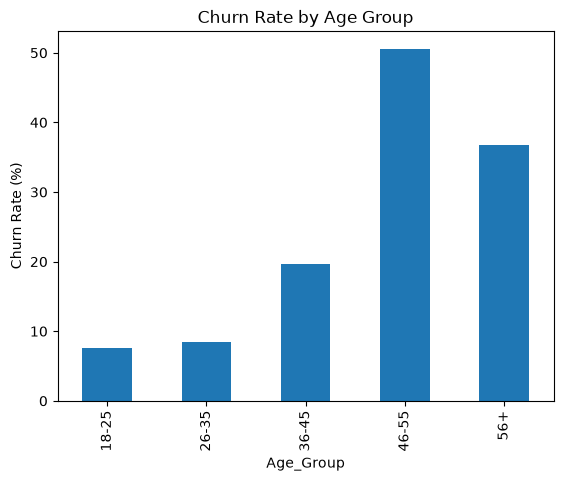

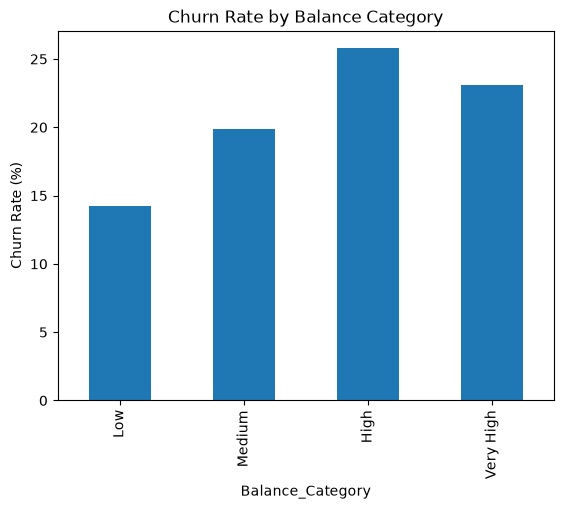

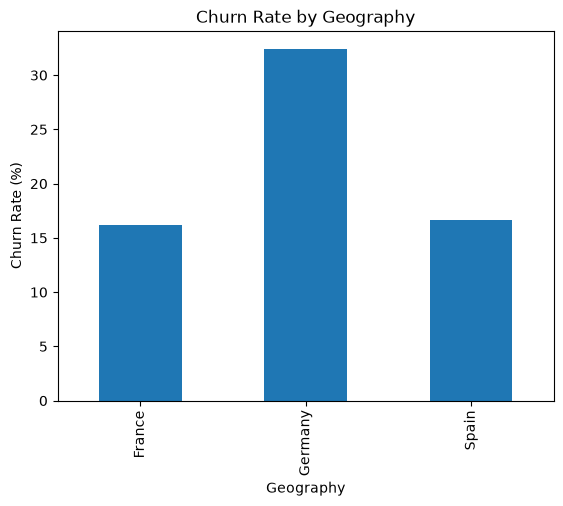

In [5]:
import matplotlib.pyplot as plt

# Question 1
age_churn.plot(kind="bar", title="Churn Rate by Age Group")
plt.ylabel("Churn Rate (%)")
plt.show()

# Question 2
df.groupby("Balance_Category", observed=False)["Exited"].mean().mul(100).plot(
    kind="bar", title="Churn Rate by Balance Category"
)
plt.ylabel("Churn Rate (%)")
plt.show()

# Question 3
region_churn.plot(kind="bar", title="Churn Rate by Geography")
plt.ylabel("Churn Rate (%)")
plt.show()